# 05 — Time-Aware Model Selection and Calibration

This notebook turns the preliminary validation ablation into a controlled model-selection checkpoint.

## Objectives

1. Tune shortlisted Logistic Regression and Random Forest candidates using expanding-window folds inside the 14 training days.
2. Fit probability calibrators from out-of-fold training predictions only.
3. Compare uncalibrated, sigmoid, and isotonic probabilities on the supplied validation period.
4. Select one candidate and an F1 operating threshold per horizon using validation data.
5. Keep all test predictors and outcomes sealed.

The resulting choices are still validation decisions, not final performance claims.

In [1]:
from pathlib import Path
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline

RANDOM_SEED = 42
HORIZONS = (5, 30, 60)

project_root_override = os.environ.get("LIMIT_ORDER_PROJECT_ROOT")
PROJECT_ROOT = Path(project_root_override) if project_root_override else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from history_features import add_order_side_features, build_history_features
from modeling import (
    FEATURE_SETS,
    add_oriented_static_features,
    build_preprocessor,
    probability_metrics,
)

warnings.filterwarnings("ignore", category=FutureWarning)

excel_files = sorted(RAW_DIR.glob("*.xlsx"))
json_files = sorted(list(RAW_DIR.glob("*.json")) + list(RAW_DIR.glob("*.json.gz")))
assert len(excel_files) == 1
assert len(json_files) == 1
EXCEL_PATH = excel_files[0]
JSON_PATH = json_files[0]

print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_SEED)
print("Test target columns requested:", 0)

Project root: /Users/yaya/Documents/GitHub/limit-order-fill-prediction
Random seed: 42
Test target columns requested: 0


In [2]:
orders = pd.read_excel(EXCEL_PATH, sheet_name="Orders")
split_normalized = orders["data_split"].astype(str).str.lower()

test_reservation = orders.loc[
    split_normalized.eq("test"),
    ["order_id", "data_split"],
].copy()
development_orders = orders.loc[
    split_normalized.isin(["train", "validation"])
].copy()
del orders

assert len(development_orders) == 8_500
assert len(test_reservation) == 1_500

history_started = time.perf_counter()
history_features = build_history_features(JSON_PATH)
history_seconds = time.perf_counter() - history_started

check_columns = [column for column in history_features if column.startswith("check_")]
assert len(history_features) == 10_000
assert history_features["order_id"].is_unique
assert history_features["history_snapshot_count"].eq(50).all()
assert history_features[check_columns].all().all()

development = development_orders.merge(
    history_features,
    on="order_id",
    how="left",
    validate="one_to_one",
)
development = add_order_side_features(development)
development = add_oriented_static_features(development)

assert development[FEATURE_SETS["D_full_history"]].notna().all().all()

print("Development rows:", len(development))
print("Reserved test rows:", len(test_reservation))
print("History build seconds:", round(history_seconds, 2))

Development rows: 8500
Reserved test rows: 1500
History build seconds: 7.28


## Expanding-window training folds

The 14 supplied training days remain chronological. Each fold trains on all earlier days and validates on the next two days:

- days 1–6 → days 7–8
- days 1–8 → days 9–10
- days 1–10 → days 11–12
- days 1–12 → days 13–14

Eligibility is applied separately inside each horizon and fold.

In [3]:
training_rows = development.loc[
    development["data_split"].astype(str).str.lower().eq("train")
].copy()
training_rows["trading_day_parsed"] = pd.to_datetime(training_rows["trading_day"])

training_days = sorted(training_rows["trading_day_parsed"].unique())
assert len(training_days) == 14

fold_day_specs = [
    (training_days[:6], training_days[6:8]),
    (training_days[:8], training_days[8:10]),
    (training_days[:10], training_days[10:12]),
    (training_days[:12], training_days[12:14]),
]

fold_rows = []
for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"
    for fold_number, (fit_days, score_days) in enumerate(fold_day_specs, start=1):
        fit_mask = training_rows["trading_day_parsed"].isin(fit_days) & training_rows[eligibility].eq(1)
        score_mask = training_rows["trading_day_parsed"].isin(score_days) & training_rows[eligibility].eq(1)
        fold_rows.append({
            "horizon_seconds": horizon,
            "fold": fold_number,
            "fit_days": len(fit_days),
            "score_days": len(score_days),
            "fit_rows": int(fit_mask.sum()),
            "score_rows": int(score_mask.sum()),
            "fit_rate": training_rows.loc[fit_mask, target].mean(),
            "score_rate": training_rows.loc[score_mask, target].mean(),
        })

fold_summary = pd.DataFrame(fold_rows)
fold_summary.round(4)

,horizon_seconds,fold,fit_days,score_days,fit_rows,score_rows,fit_rate,score_rate
0,5,1,6,2,2925,979,0.1056,0.0858
1,5,2,8,2,3904,961,0.1007,0.1082
2,5,3,10,2,4865,975,0.1022,0.1097
3,5,4,12,2,5840,967,0.1034,0.1107
4,30,1,6,2,2648,890,0.4173,0.3933
5,30,2,8,2,3538,878,0.4112,0.4328
6,30,3,10,2,4416,887,0.4155,0.4307
7,30,4,12,2,5303,870,0.4181,0.4184
8,60,1,6,2,2473,831,0.6276,0.5921
9,60,2,8,2,3304,822,0.6186,0.6691


## Candidate models and tuning grids

Notebook 04 showed that Decision Tree underperformed, so this stage retains:

- Logistic Regression with feature sets B, C, and D;
- Random Forest with feature sets C and D.

Including D again tests whether stronger regularization or different forest complexity can rescue the history signal. Mean internal-fold PR-AUC is the tuning criterion; mean Brier score breaks ties.

In [4]:
CANDIDATES = [
    {"candidate": "B_logistic", "feature_set": "B_order_lob", "model": "logistic_regression"},
    {"candidate": "C_logistic", "feature_set": "C_order_lob_flow", "model": "logistic_regression"},
    {"candidate": "D_logistic", "feature_set": "D_full_history", "model": "logistic_regression"},
    {"candidate": "C_random_forest", "feature_set": "C_order_lob_flow", "model": "random_forest"},
    {"candidate": "D_random_forest", "feature_set": "D_full_history", "model": "random_forest"},
]

LOGISTIC_GRID = [
    {"C": value}
    for value in (0.03, 0.1, 0.3, 1.0, 3.0)
]
FOREST_GRID = [
    {"max_depth": 6, "min_samples_leaf": 10, "max_features": "sqrt"},
    {"max_depth": 10, "min_samples_leaf": 5, "max_features": "sqrt"},
    {"max_depth": None, "min_samples_leaf": 5, "max_features": "sqrt"},
    {"max_depth": None, "min_samples_leaf": 20, "max_features": 0.5},
]


def parameter_grid(model_name):
    return LOGISTIC_GRID if model_name == "logistic_regression" else FOREST_GRID


def build_estimator(feature_set_name, model_name, parameters):
    features = FEATURE_SETS[feature_set_name]
    if model_name == "logistic_regression":
        model = LogisticRegression(
            C=parameters["C"],
            max_iter=3000,
            solver="lbfgs",
            random_state=RANDOM_SEED,
        )
    else:
        model = RandomForestClassifier(
            n_estimators=250,
            max_depth=parameters["max_depth"],
            min_samples_leaf=parameters["min_samples_leaf"],
            max_features=parameters["max_features"],
            n_jobs=-1,
            random_state=RANDOM_SEED,
        )
    return Pipeline([
        ("preprocessing", build_preprocessor(features)),
        ("model", model),
    ])

In [5]:
tuning_started = time.perf_counter()
tuning_rows = []

for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"

    for candidate in CANDIDATES:
        features = FEATURE_SETS[candidate["feature_set"]]
        for parameters in parameter_grid(candidate["model"]):
            fold_metrics = []
            for fold_number, (fit_days, score_days) in enumerate(fold_day_specs, start=1):
                fit_mask = (
                    training_rows["trading_day_parsed"].isin(fit_days)
                    & training_rows[eligibility].eq(1)
                )
                score_mask = (
                    training_rows["trading_day_parsed"].isin(score_days)
                    & training_rows[eligibility].eq(1)
                )

                estimator = build_estimator(
                    candidate["feature_set"],
                    candidate["model"],
                    parameters,
                )
                estimator.fit(
                    training_rows.loc[fit_mask, features],
                    training_rows.loc[fit_mask, target].astype(int),
                )
                probability = estimator.predict_proba(
                    training_rows.loc[score_mask, features]
                )[:, 1]
                y_score = training_rows.loc[score_mask, target].astype(int).to_numpy()
                fold_metrics.append({
                    "pr_auc": average_precision_score(y_score, probability),
                    "roc_auc": roc_auc_score(y_score, probability),
                    "brier_score": brier_score_loss(y_score, probability),
                })

            fold_frame = pd.DataFrame(fold_metrics)
            tuning_rows.append({
                "horizon_seconds": horizon,
                **candidate,
                "parameters": parameters,
                "mean_fold_pr_auc": fold_frame["pr_auc"].mean(),
                "std_fold_pr_auc": fold_frame["pr_auc"].std(ddof=1),
                "mean_fold_roc_auc": fold_frame["roc_auc"].mean(),
                "mean_fold_brier": fold_frame["brier_score"].mean(),
            })

tuning_results = pd.DataFrame(tuning_rows)
tuning_seconds = time.perf_counter() - tuning_started

selected_hyperparameters = (
    tuning_results
    .sort_values(
        ["horizon_seconds", "candidate", "mean_fold_pr_auc", "mean_fold_brier"],
        ascending=[True, True, False, True],
    )
    .groupby(["horizon_seconds", "candidate"], as_index=False)
    .first()
)

print("Internal models fitted:", sum(len(parameter_grid(c["model"])) for c in CANDIDATES) * len(HORIZONS) * len(fold_day_specs))
print("Tuning seconds:", round(tuning_seconds, 2))
selected_hyperparameters[
    [
        "horizon_seconds",
        "candidate",
        "feature_set",
        "model",
        "parameters",
        "mean_fold_pr_auc",
        "std_fold_pr_auc",
        "mean_fold_roc_auc",
        "mean_fold_brier",
    ]
].round(4)

Internal models fitted: 276
Tuning seconds: 65.15


,horizon_seconds,candidate,feature_set,model,parameters,mean_fold_pr_auc,std_fold_pr_auc,mean_fold_roc_auc,mean_fold_brier
0,5,B_logistic,B_order_lob,logistic_regression,{'C': 3.0},0.1737,0.0378,0.6462,0.0909
1,5,C_logistic,C_order_lob_flow,logistic_regression,{'C': 0.03},0.1822,0.0463,0.6559,0.0905
2,5,C_random_forest,C_order_lob_flow,random_forest,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.1858,0.0355,0.6245,0.0912
3,5,D_logistic,D_full_history,logistic_regression,{'C': 0.03},0.1816,0.0421,0.6490,0.0906
4,5,D_random_forest,D_full_history,random_forest,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.1884,0.0348,0.6220,0.0910
5,30,B_logistic,B_order_lob,logistic_regression,{'C': 0.3},0.5905,0.0175,0.6598,0.2237
6,30,C_logistic,C_order_lob_flow,logistic_regression,{'C': 0.1},0.6086,0.0130,0.6782,0.2201
7,30,C_random_forest,C_order_lob_flow,random_forest,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.6117,0.0084,0.6812,0.2188
8,30,D_logistic,D_full_history,logistic_regression,{'C': 0.03},0.6009,0.0151,0.6717,0.2218
9,30,D_random_forest,D_full_history,random_forest,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.6141,0.0099,0.6816,0.2186


## Out-of-fold calibration

For each tuned candidate, the four expanding folds produce out-of-fold training probabilities. Sigmoid and isotonic mappings are fitted only to those probabilities. The tuned base estimator is then refitted on all eligible training rows and scored on validation.

Validation data choose the calibration method; they never fit the calibrator itself.

In [6]:
def clipped_logit(probability):
    clipped = np.clip(np.asarray(probability), 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped)).reshape(-1, 1)


def expected_calibration_error(y_true, probability, bins=10):
    y_true = np.asarray(y_true)
    probability = np.asarray(probability)
    edges = np.linspace(0, 1, bins + 1)
    assignments = np.clip(np.digitize(probability, edges[1:-1]), 0, bins - 1)
    ece = 0.0
    for bin_number in range(bins):
        mask = assignments == bin_number
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - probability[mask].mean())
    return float(ece)


def apply_calibration(method, raw_probability, sigmoid_model=None, isotonic_model=None):
    if method == "none":
        return np.asarray(raw_probability)
    if method == "sigmoid":
        return sigmoid_model.predict_proba(clipped_logit(raw_probability))[:, 1]
    return isotonic_model.predict(raw_probability)


calibration_started = time.perf_counter()
calibration_rows = []
validation_prediction_store = {}

for selection in selected_hyperparameters.to_dict("records"):
    horizon = selection["horizon_seconds"]
    candidate_name = selection["candidate"]
    feature_set_name = selection["feature_set"]
    model_name = selection["model"]
    parameters = selection["parameters"]
    features = FEATURE_SETS[feature_set_name]
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"

    oof_probabilities = []
    oof_targets = []
    for fit_days, score_days in fold_day_specs:
        fit_mask = (
            training_rows["trading_day_parsed"].isin(fit_days)
            & training_rows[eligibility].eq(1)
        )
        score_mask = (
            training_rows["trading_day_parsed"].isin(score_days)
            & training_rows[eligibility].eq(1)
        )
        estimator = build_estimator(feature_set_name, model_name, parameters)
        estimator.fit(
            training_rows.loc[fit_mask, features],
            training_rows.loc[fit_mask, target].astype(int),
        )
        oof_probabilities.append(
            estimator.predict_proba(training_rows.loc[score_mask, features])[:, 1]
        )
        oof_targets.append(training_rows.loc[score_mask, target].astype(int).to_numpy())

    oof_probability = np.concatenate(oof_probabilities)
    oof_target = np.concatenate(oof_targets)

    sigmoid_model = LogisticRegression(C=1_000_000, solver="lbfgs", max_iter=2000)
    sigmoid_model.fit(clipped_logit(oof_probability), oof_target)
    isotonic_model = IsotonicRegression(out_of_bounds="clip")
    isotonic_model.fit(oof_probability, oof_target)

    full_train_mask = training_rows[eligibility].eq(1)
    official_validation_mask = (
        development["data_split"].astype(str).str.lower().eq("validation")
        & development[eligibility].eq(1)
    )
    y_train = training_rows.loc[full_train_mask, target].astype(int)
    y_validation = development.loc[official_validation_mask, target].astype(int).to_numpy()

    final_estimator = build_estimator(feature_set_name, model_name, parameters)
    final_estimator.fit(training_rows.loc[full_train_mask, features], y_train)
    raw_validation_probability = final_estimator.predict_proba(
        development.loc[official_validation_mask, features]
    )[:, 1]

    for method in ("none", "sigmoid", "isotonic"):
        calibrated_probability = apply_calibration(
            method,
            raw_validation_probability,
            sigmoid_model=sigmoid_model,
            isotonic_model=isotonic_model,
        )
        metrics = probability_metrics(y_validation, calibrated_probability)
        calibration_rows.append({
            "horizon_seconds": horizon,
            "candidate": candidate_name,
            "feature_set": feature_set_name,
            "model": model_name,
            "calibration": method,
            "parameters": parameters,
            "ece_10": expected_calibration_error(y_validation, calibrated_probability),
            **metrics,
        })
        validation_prediction_store[(horizon, candidate_name, method)] = {
            "order_id": development.loc[official_validation_mask, "order_id"].to_numpy(),
            "y_true": y_validation.copy(),
            "probability": calibrated_probability.copy(),
            "raw_probability": raw_validation_probability.copy(),
        }

calibration_results = pd.DataFrame(calibration_rows)
calibration_seconds = time.perf_counter() - calibration_started
print("Validation candidate/calibration combinations:", len(calibration_results))
print("Calibration stage seconds:", round(calibration_seconds, 2))
print("Test predictions produced:", 0)

Validation candidate/calibration combinations: 45
Calibration stage seconds: 52.06
Test predictions produced: 0


In [7]:
best_calibration_per_candidate = (
    calibration_results
    .sort_values(
        ["horizon_seconds", "candidate", "brier_score", "ece_10"],
        ascending=[True, True, True, True],
    )
    .groupby(["horizon_seconds", "candidate"], as_index=False)
    .first()
)

best_calibration_per_candidate[
    [
        "horizon_seconds",
        "candidate",
        "feature_set",
        "model",
        "calibration",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10",
    ]
].round(4)

,horizon_seconds,candidate,feature_set,model,calibration,roc_auc,pr_auc,brier_score,ece_10
0,5,B_logistic,B_order_lob,logistic_regression,sigmoid,0.6647,0.2466,0.0872,0.0272
1,5,C_logistic,C_order_lob_flow,logistic_regression,sigmoid,0.6695,0.2340,0.0875,0.0092
2,5,C_random_forest,C_order_lob_flow,random_forest,isotonic,0.6440,0.1979,0.0873,0.0142
3,5,D_logistic,D_full_history,logistic_regression,sigmoid,0.6531,0.1983,0.0887,0.0095
4,5,D_random_forest,D_full_history,random_forest,isotonic,0.6427,0.1925,0.0881,0.0128
5,30,B_logistic,B_order_lob,logistic_regression,sigmoid,0.6744,0.5995,0.2158,0.0403
6,30,C_logistic,C_order_lob_flow,logistic_regression,sigmoid,0.6816,0.6001,0.2148,0.0411
7,30,C_random_forest,C_order_lob_flow,random_forest,sigmoid,0.6822,0.6043,0.2138,0.0376
8,30,D_logistic,D_full_history,logistic_regression,sigmoid,0.6749,0.5957,0.2162,0.0462
9,30,D_random_forest,D_full_history,random_forest,sigmoid,0.6808,0.6013,0.2141,0.0490


In [8]:
# Primary selection: highest validation PR-AUC after choosing each candidate's
# lowest-Brier calibration. Brier score breaks exact numerical ties.
selected_models = (
    best_calibration_per_candidate
    .sort_values(
        ["horizon_seconds", "pr_auc", "brier_score"],
        ascending=[True, False, True],
    )
    .groupby("horizon_seconds", as_index=False)
    .first()
)

selected_models[
    [
        "horizon_seconds",
        "candidate",
        "feature_set",
        "model",
        "calibration",
        "parameters",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10",
    ]
].round(4)

,horizon_seconds,candidate,feature_set,model,calibration,parameters,roc_auc,pr_auc,brier_score,ece_10
0,5,B_logistic,B_order_lob,logistic_regression,sigmoid,{'C': 3.0},0.6647,0.2466,0.0872,0.0272
1,30,C_random_forest,C_order_lob_flow,random_forest,sigmoid,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.6822,0.6043,0.2138,0.0376
2,60,C_random_forest,C_order_lob_flow,random_forest,sigmoid,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.7015,0.7976,0.2108,0.0597


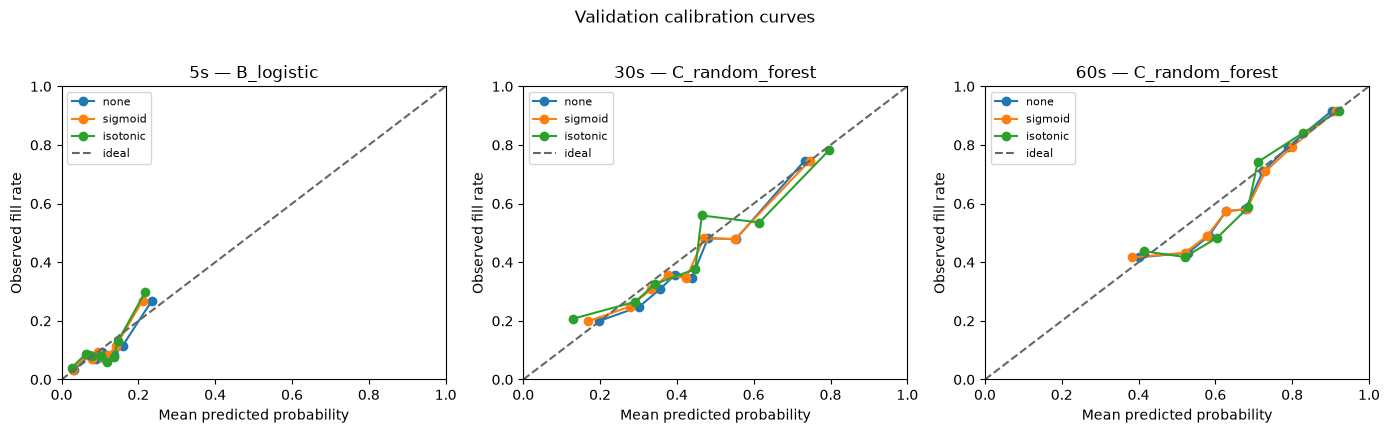

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, selection in zip(axes, selected_models.to_dict("records")):
    horizon = selection["horizon_seconds"]
    candidate = selection["candidate"]
    for method in ("none", "sigmoid", "isotonic"):
        stored = validation_prediction_store[(horizon, candidate, method)]
        observed, predicted = calibration_curve(
            stored["y_true"],
            stored["probability"],
            n_bins=8,
            strategy="quantile",
        )
        ax.plot(predicted, observed, marker="o", label=method)

    ax.plot([0, 1], [0, 1], linestyle="--", color="0.4", label="ideal")
    ax.set_title(f"{horizon}s — {candidate}")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed fill rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

fig.suptitle("Validation calibration curves", y=1.02)
fig.tight_layout()
plt.show()

## Validation threshold selection

For each selected model, the threshold maximizes validation F1. This is an explicit equal-balance choice between precision and recall. The threshold and its metrics must be carried unchanged into the final test evaluation.

In [10]:
threshold_rows = []

for selection in selected_models.to_dict("records"):
    horizon = selection["horizon_seconds"]
    key = (horizon, selection["candidate"], selection["calibration"])
    stored = validation_prediction_store[key]
    y_true = stored["y_true"]
    probability = stored["probability"]

    precision_values, recall_values, thresholds = precision_recall_curve(y_true, probability)
    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / np.maximum(precision_values[:-1] + recall_values[:-1], 1e-12)
    )
    best_index = int(np.nanargmax(f1_values))
    selected_threshold = float(thresholds[best_index])
    metrics = probability_metrics(y_true, probability, threshold=selected_threshold)
    predictions = (probability >= selected_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    threshold_rows.append({
        "horizon_seconds": horizon,
        "candidate": selection["candidate"],
        "feature_set": selection["feature_set"],
        "model": selection["model"],
        "calibration": selection["calibration"],
        "parameters": selection["parameters"],
        "selected_threshold": selected_threshold,
        "predicted_fill_rate": predictions.mean(),
        "true_fill_rate": y_true.mean(),
        "ece_10": expected_calibration_error(y_true, probability),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        **metrics,
    })

threshold_results = pd.DataFrame(threshold_rows)
threshold_results.round(4)

,horizon_seconds,candidate,feature_set,model,calibration,parameters,selected_threshold,predicted_fill_rate,true_fill_rate,ece_10,...,fp,fn,tp,roc_auc,pr_auc,brier_score,accuracy,precision,recall,f1
0,5,B_logistic,B_order_lob,logistic_regression,sigmoid,{'C': 3.0},0.1891,0.0729,0.1024,0.0272,...,65,108,41,0.6647,0.2466,0.0872,0.8811,0.3868,0.2752,0.3216
1,30,C_random_forest,C_order_lob_flow,random_forest,sigmoid,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.3472,0.6488,0.3958,0.0376,...,445,110,414,0.6822,0.6043,0.2138,0.5808,0.4820,0.7901,0.5987
2,60,C_random_forest,C_order_lob_flow,random_forest,sigmoid,"{'max_depth': None, 'min_samples_leaf': 20, 'm...",0.3434,0.9637,0.6140,0.0597,...,445,11,751,0.7015,0.7976,0.2108,0.6326,0.6279,0.9856,0.7671


In [11]:
print("Selected validation policy:")
for row in threshold_results.itertuples(index=False):
    print(
        f"{row.horizon_seconds:>2}s | {row.candidate:<16} | "
        f"calibration={row.calibration:<8} | threshold={row.selected_threshold:.3f} | "
        f"PR-AUC={row.pr_auc:.4f} | Brier={row.brier_score:.4f} | "
        f"precision={row.precision:.3f} | recall={row.recall:.3f} | F1={row.f1:.3f} | "
        f"parameters={row.parameters}"
    )

Selected validation policy:
 5s | B_logistic       | calibration=sigmoid  | threshold=0.189 | PR-AUC=0.2466 | Brier=0.0872 | precision=0.387 | recall=0.275 | F1=0.322 | parameters={'C': 3.0}
30s | C_random_forest  | calibration=sigmoid  | threshold=0.347 | PR-AUC=0.6043 | Brier=0.2138 | precision=0.482 | recall=0.790 | F1=0.599 | parameters={'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.5}
60s | C_random_forest  | calibration=sigmoid  | threshold=0.343 | PR-AUC=0.7976 | Brier=0.2108 | precision=0.628 | recall=0.986 | F1=0.767 | parameters={'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.5}


In [12]:
artifact_dir_override = os.environ.get("LIMIT_ORDER_ARTIFACT_DIR")
ARTIFACT_DIR = (
    Path(artifact_dir_override)
    if artifact_dir_override
    else PROJECT_ROOT / "results"
)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

candidate_summary_path = ARTIFACT_DIR / "validation_candidate_summary.csv"
policy_path = ARTIFACT_DIR / "selected_model_policy.json"

best_calibration_per_candidate.to_csv(candidate_summary_path, index=False)


def to_builtin(value):
    if isinstance(value, dict):
        return {str(key): to_builtin(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_builtin(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    return value


policy = {
    "status": "validation_selected_test_not_evaluated",
    "random_seed": RANDOM_SEED,
    "selection_rule": (
        "For each candidate choose the calibration method with the lowest validation "
        "Brier score; then choose the candidate with the highest validation PR-AUC."
    ),
    "threshold_rule": "Maximize validation F1.",
    "horizons": {},
}

for row in threshold_results.to_dict("records"):
    horizon = str(int(row["horizon_seconds"]))
    policy["horizons"][horizon] = {
        "candidate": row["candidate"],
        "feature_set": row["feature_set"],
        "model": row["model"],
        "parameters": to_builtin(row["parameters"]),
        "calibration": row["calibration"],
        "selected_threshold": float(row["selected_threshold"]),
        "validation_metrics": {
            "roc_auc": float(row["roc_auc"]),
            "pr_auc": float(row["pr_auc"]),
            "brier_score": float(row["brier_score"]),
            "ece_10": float(row["ece_10"]),
            "accuracy": float(row["accuracy"]),
            "precision": float(row["precision"]),
            "recall": float(row["recall"]),
            "f1": float(row["f1"]),
        },
    }

policy_path.write_text(json.dumps(policy, indent=2) + "\n")

print("Saved validation candidate summary:", candidate_summary_path)
print("Saved frozen model policy:", policy_path)

Saved validation candidate summary: /private/tmp/model-selection-artifacts/validation_candidate_summary.csv
Saved frozen model policy: /private/tmp/model-selection-artifacts/selected_model_policy.json


## Next checkpoint

Commit the selected feature set, model hyperparameters, calibration method, and threshold for each horizon before opening the test set. The next notebook may then perform the single final test evaluation, including side, market-activity, and trading-day stability checks.

Do not revisit model choices after viewing the test results.